# <font color="#0b486b">FIT3181 | FIT5215: Deep Learning (2026)</font>
***

*CE/Lecturer (Clayton):* **Dr [Trung Le](mailto:trunglm@monash.edu)** <br/>
*Lecturer (Clayton):* **Dr [Binh Nguyen](mailto:binh.nguyen1@monash.edu)** <br/>
*Lecturer (Malaysia):*  **Dr [Arghya Pal](mailto:arghya.pal@monash.edu)**, **Dr [Sailaja Rajanala](mailto:sailaja.rajanala@monash.edu)**, **Dr [Sicily Fung Fung Ting](mailto:ting.fung@monash.edu)** <br/>
*Head Tutor (Clayton):* **Mr [Minh Vo](mailto:minh.vo1@monash.edu)** (FIT3181), **Dr [Ruda Nie H](mailto:rudanie.h@monash.edu)** (FIT5215)<br/> <br/>

Faculty of Information Technology, Monash University, Australia
***

# <font color="#0b486b">Tutorial 07b: RNN for Sentiment Analysis in Pytorch</font><font color="red"></font> #

This tutorial shows you how to apply Recurrent Neural Networks in sequence classification. Particularly, we are going to explore how to implement an RNN for sentiment analysis with the dataset *IMDB movie review*.

## <font color="#0b486b">Part I: Implementation using existed dataset stored in a storage device</font><font color="red">*****</font> ##

In many real-world projects with recurrent models, you possess the data stored in a storage device. In this case, you are required to preprocess data from scratch. In what follows, we study how to cope with this situation.

### <font color="#0b486b">I.1. The pipeline of sentence classification</font> ###


In what follows, we present the common pipeline of sentence classification (e.g., sentiment analysis or review analysis) from how to transform sentences as sequences of words to sequences of numbers to feed into a recurrent neural network.

Assume that we are learning from a tiny movie review dataset with the following sentences with labels:

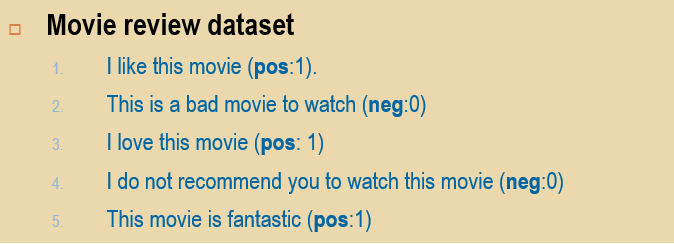

We next extract the important or most frequent words to build up the vocabulary. Let's assume that we have the following vocabulary:

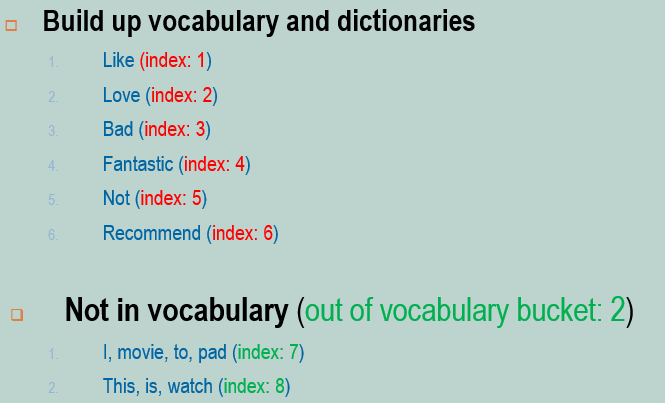

Because the vocabulary does not contain all words in the dataset, there are some words being out of the vocabulary and further assume that we employ two indices (e.g., 7 and 8) for out of vocabulary bucket. Now each word in the dataset is associated with one index which is later useful to transform sentences into sequences of indices. In addition, from the vocabulary we can conduct two dictionaries:
- **word2indx**: keys are words and values are indices.
- **indx2word**: keys are indices and values are words.

Next, we assume that embedding size is $5$, meaning that each word will be embedded into a 5-dim vector space (each word becomes a 5-dim vector). For this purpose, we employ an embedding matrix as follows:

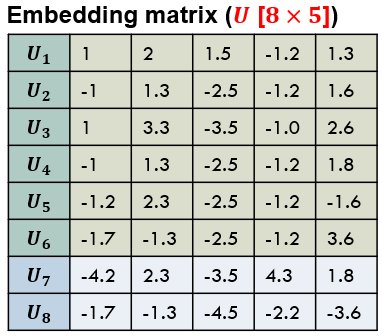

Note that at first, this embedding matrix will be `randomly initialized` and then will be `learned` during the training process. We now explain how to use this embedding matrix to embed a mini-batch of two sentences to a 3D tensor. Assume that we have two following sentences in the mini-batch:
1. `I like this movie`.
2. `This is a bad movie to watch`.

Assume that we set sequence length (or timesteps) to 6. We need to pad the first sentence and truncate the second one as:
1.  `I like this movie` **pad pad**.
2. `This is a bad movie to`.

We next use the vocabulary and word2indx dictionary to transform two sentences into two sequences of indices in the form of a 2D tensor with the shape $[batch\_size, seq\_length]$.
1. `I like this movie` $\rightarrow$ $[7, 1, 8, 7, 7, 7]$.
2. `This is a bad movie to watch` $\rightarrow$ $[8, 8, 7, 3, 7, 7]$.

Next, we use embedding matrix to transform indices to embedding vectors as:
1. `I like this movie` $\rightarrow$ $[7, 1, 8, 7, 7, 7]$ $\rightarrow$ $[U_7, U_1, U_8, U_7, U_7, U_7]$.
2. `This is a bad movie to watch` $\rightarrow$ $[8, 8, 7, 3, 7, 7]$ $\rightarrow$ $[U_8, U_8, U_7, U_3, U_7, U_7]$.

We then concatenate two sequences of embedding vectors to a 3D tensor with the shape $[batch\_size, seq\_length, embed\_size]$. This 3D tensor will be later fed to subsequent recurrent layers of cells. Note that this embedding process will be performed automatically using the embedding layer.
-  `torch.nn.Embedding`.

The following figure details the entire process from inputting a batch of sentences, embedding to a 3D tensor, to feeding through recurrent layers.

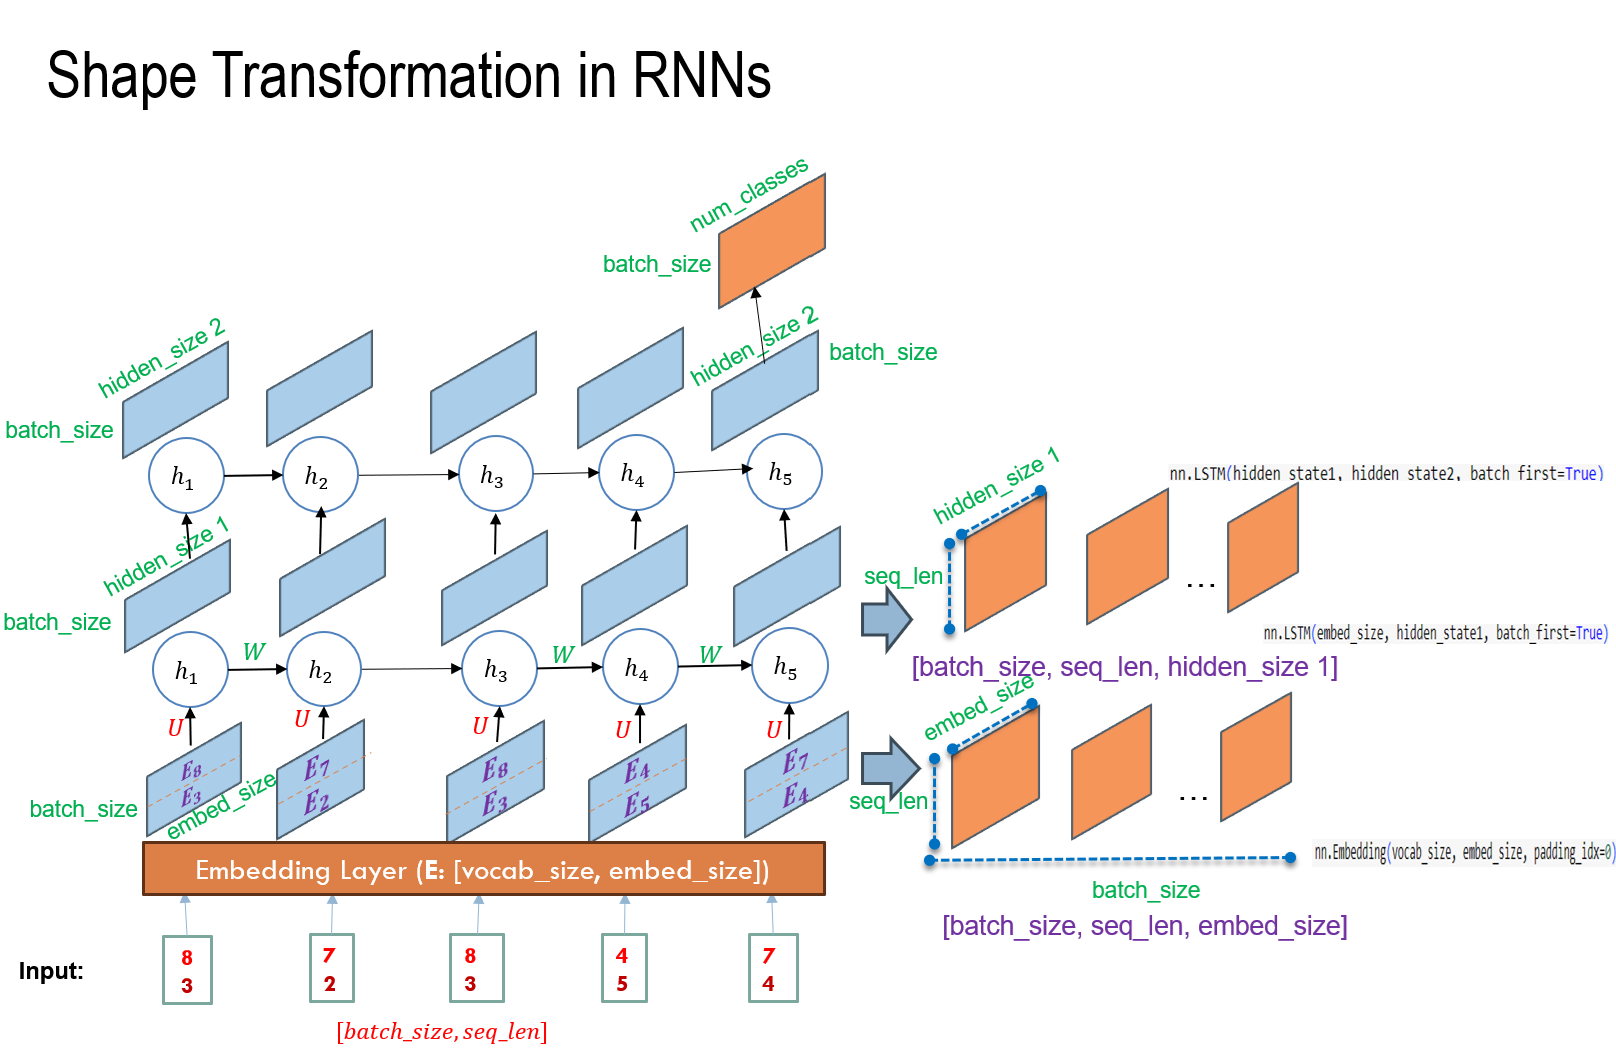

### <font color="#0b486b">I.2. Download, play around, and preprocess with the dataset</font> ###

Assume that our dataset can be found online at a specific URL. We need to write code to download the dataset and store it on our storage device.

In [ ]:
import torch
import os
import numpy as np

np.random.seed(123)
torch.manual_seed(123)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

The function *download_and_read(url)* supports us to download the dataset at the specific url and store to the folder *datasets* inside the current directory.

In [ ]:
import os
import requests
from torchvision.datasets.utils import download_and_extract_archive

def download_and_read(url):
    # download and extract the file
    download_and_extract_archive(url, download_root='datasets')

    local_file = url.split('/')[-1]
    local_file = local_file.replace("%20", " ")
    local_folder = os.path.join("datasets", local_file.split('.')[0])

    labeled_sentences = []
    for labeled_filename in os.listdir(local_folder):
        if labeled_filename.endswith("_labelled.txt"):
            with open(os.path.join(local_folder, labeled_filename), "r") as f:
                for line in f:
                    sentence, label = line.strip().split('\t')
                    labeled_sentences.append((sentence, label))
    return labeled_sentences

We now employ the above function to download the online dataset and store it on the hard disk. At this step, we also have the dataset including sentences and labels.

In [ ]:
labeled_sentences = download_and_read("https://archive.ics.uci.edu/ml/machine-learning-databases/" + "00331/sentiment%20labelled%20sentences.zip")

84.2kB [00:00, 2.76MB/s]


In [ ]:
sentences = [s for (s, l) in labeled_sentences]
labels = [int(l) for (s, l) in labeled_sentences]

In [ ]:
for (s,l) in zip(sentences[0:5], labels[0:5]):
    print("Sentence: {}".format(s))
    print("Label: {}".format(l))
    print("\n")

Sentence: So there is no way for me to plug it in here in the US unless I go by a converter.
Label: 0


Sentence: Good case, Excellent value.
Label: 1


Sentence: Great for the jawbone.
Label: 1


Sentence: Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
Label: 0


Sentence: The mic is great.
Label: 1




We need to inspect the sentences in the dataset to work out the vocabulary and two dictionaries: *word2idx* and *idx2word*.

**Note:** In this tutorial, we use the *word_tokenize* function from NLTK to tokenize a sentence into words. Alternatively, we can use similar functions from other libraries, such as torchtext. For example:

*from torchtext.data.utils import get_tokenizer*<br>
*tokenizer = get_tokenizer("basic_english")*

In [ ]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
from collections import Counter
from nltk.tokenize import word_tokenize

# create a custom dataset class
class TextDataset():
    def __init__(self, sentences):
        self.sentences = sentences
        self.word2idx = {}
        self.idx2word = {}

        # create vocabulary
        word_freq = Counter()
        for sent in self.sentences:
            #tokens consists of words in a sentence, e.g., ['think', 'of', 'the', 'film', 'being', 'like', 'a', 'dream', '.']
            tokens = word_tokenize(sent.lower()) # convert to lowercase and tokenize
            word_freq.update(tokens)

        # vocabulary sorted by frequency (most common words first)
        vocabulary = [word for word, freq in word_freq.most_common()]

        self.word2idx = {word: idx for idx, word in enumerate(vocabulary)}
        self.idx2word = {idx: word for word, idx in self.word2idx.items()}

In [ ]:
# create an instance of the dataset class
dataset = TextDataset(sentences)

word2idx = dataset.word2idx
idx2word = dataset.idx2word

In [ ]:
print(list(word2idx.items())[0:10])

[('.', 0), ('the', 1), (',', 2), ('and', 3), ('i', 4), ('a', 5), ('it', 6), ('is', 7), ('to', 8), ('this', 9)]


In [ ]:
print(list(idx2word.items())[0:10])

[(0, '.'), (1, 'the'), (2, ','), (3, 'and'), (4, 'i'), (5, 'a'), (6, 'it'), (7, 'is'), (8, 'to'), (9, 'this')]


We need to choose the sequence length for our RNN. The sequence length should be chosen so that the truncated sentences with the sequence length contain substantial information for our task. In what follows, we investigate the percentiles to decide the sequence length.

In [ ]:
seq_lengths = np.array([len(s.split()) for s in sentences])
print([(p, np.percentile(seq_lengths, p)) for p in [75, 80, 90, 95, 99, 100]])

[(75, np.float64(16.0)), (80, np.float64(18.0)), (90, np.float64(22.0)), (95, np.float64(26.0)), (99, np.float64(36.0)), (100, np.float64(71.0))]


We decide to choose $max\_seqlen=64$ which is the percentile of $>99\%$, hence covering almost all sentences. We then transform the dataset of sentences to that of indices. Finally, we create a Pytorch dataset (i.e., stored in the variable *dataset*). Tensorflow dataset assists us in manipulating the data and splitting it into mini-batches later.

We now split the dataset to train_dataset, val_dataset, and test_dataset. Subsequently, we create batch datasets for training, valid, and test sets.

In [ ]:
from collections import Counter

# tokenizer function using split
def simple_tokenizer(text):
    return word_tokenize(text.lower())

# generator function to yield tokens
def yield_tokens(data_iter):
    for text in data_iter:
        yield simple_tokenizer(text)

# build vocabulary using Counter and add special tokens
def build_vocab_from_iterator(iterator, specials=None):
    word_freq = Counter()
    for tokens in iterator:
        word_freq.update(tokens)

    # sort words by frequency (most common first) and include special tokens
    sorted_vocab = specials + [word for word, freq in word_freq.most_common()]
    vocab = {word: idx for idx, word in enumerate(sorted_vocab)}

    return vocab

# build the vocabulary
vocab = build_vocab_from_iterator(yield_tokens(sentences), specials=["<pad>"])

# print the vocabulary and default index
print("Vocabulary:", vocab)

Vocabulary: {'<pad>': 0, '.': 1, 'the': 2, ',': 3, 'and': 4, 'i': 5, 'a': 6, 'it': 7, 'is': 8, 'to': 9, 'this': 10, 'of': 11, 'was': 12, '!': 13, 'in': 14, 'for': 15, 'not': 16, 'that': 17, "n't": 18, 'with': 19, 'my': 20, 'very': 21, "'s": 22, 'good': 23, 'you': 24, 'on': 25, 'great': 26, 'but': 27, 'have': 28, 'are': 29, 'movie': 30, 'as': 31, 'so': 32, 'phone': 33, 'film': 34, 'all': 35, 'be': 36, 'one': 37, 'had': 38, 'at': 39, 'do': 40, 'food': 41, 'like': 42, 'just': 43, 'place': 44, 'there': 45, 'time': 46, 'were': 47, 'they': 48, 'an': 49, 'service': 50, 'we': 51, 'if': 52, 'from': 53, 'really': 54, ')': 55, 'bad': 56, 'would': 57, '(': 58, 'did': 59, 'has': 60, 'out': 61, 'well': 62, 'about': 63, 'no': 64, 'or': 65, 'your': 66, 'by': 67, 'best': 68, 'only': 69, 'here': 70, 'even': 71, '-': 72, 'ever': 73, '...': 74, 'also': 75, 'will': 76, 'back': 77, 'up': 78, 'when': 79, 'could': 80, 'me': 81, '``': 82, 'more': 83, 'than': 84, 'can': 85, 'quality': 86, 'does': 87, "'ve": 88,

In [ ]:
len(vocab)

5354

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# assume max_sequence_length is a predefined constant
max_sequence_length = 32

# tokenize sentences using split() function
tokenized_sentences = [word_tokenize(sentence.lower()) for sentence in sentences]

# transform sentences to sequences of indices (list of lists of indices)
sentences_as_ints = [[vocab[token] for token in tokens] for tokens in tokenized_sentences]

# pad and truncate sequences
padded_sequences = []
for seq in sentences_as_ints:
    if len(seq) > max_sequence_length:
        seq = seq[:max_sequence_length]

    # pad sequence to max_sequence_length
    padding_length = max_sequence_length - len(seq)
    if padding_length > 0:
        seq.extend([0] * padding_length)  # extend with padding values
    padded_sequences.append(seq)

# convert list of lists to tensor
truncated_padded_sequences = torch.tensor(padded_sequences, dtype=torch.long)

# convert labels to tensor
labels_as_ints = torch.tensor(labels)

# create dataset
dataset = TensorDataset(truncated_padded_sequences, labels_as_ints)

In [ ]:
for (ts,l,si,tps,li) in zip(tokenized_sentences[0:3], labels[0:3], sentences_as_ints[0:3], truncated_padded_sequences[0:3], labels_as_ints[0:3]):
    print("Sentence: {}".format(ts))
    print("Label: {}".format(l))
    print("si: {}".format(si))
    print("tps: {}".format(tps))
    print("li: {}".format(li))
    print("\n")

Sentence: ['so', 'there', 'is', 'no', 'way', 'for', 'me', 'to', 'plug', 'it', 'in', 'here', 'in', 'the', 'us', 'unless', 'i', 'go', 'by', 'a', 'converter', '.']
Label: 0
si: [32, 45, 8, 64, 124, 15, 81, 9, 383, 7, 14, 70, 14, 2, 193, 654, 5, 89, 67, 6, 2235, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
tps: tensor([  32,   45,    8,   64,  124,   15,   81,    9,  383,    7,   14,   70,
          14,    2,  193,  654,    5,   89,   67,    6, 2235,    1,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0])
li: 0


Sentence: ['good', 'case', ',', 'excellent', 'value', '.']
Label: 1
si: [23, 163, 3, 104, 527, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
tps: tensor([ 23, 163,   3, 104, 527,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0])
li: 1


Sentence: ['great', 'for', 'the', 'jawbone', '.']
Label: 1
si: [26, 15, 2, 1078, 1, 0, 0, 0, 0, 0, 0, 0,

In [ ]:
from torch.utils.data import random_split

# split the dataset into training, validation, and testing sets
train_size = int(0.8 * len(dataset))
val_size = int(0.1 * len(dataset))
test_size = len(dataset) - train_size - val_size

print(train_size)
print(val_size)
print(test_size)

train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size])

batch_size = 32

# create the dataloader for each set
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

2400
300
300


### <font color="#0b486b">I.2. Building up and training the model</font> ###

In what follows, we build up an RNN with the stack of two LSTM cells. The input $x$ has the shape $batch\_size \times timesteps$. The embedding layer takes the input $x$ and transforms it to 3D tensor $batch\_size \times timesteps \times embed\_size$. When declaring an embedding layer, we need to specify vocabulary size ($vocab\_size$), and the $embed\_size$.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.init as init

embed_size = 128

class Model(nn.Module):
    def __init__(self, vocab_size):
        super(Model, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=0)

        self.lstm1 = nn.LSTM(embed_size, 128, batch_first=True) #return [batch_size, seq_len, hidden_size = 128]
        self.lstm2 = nn.LSTM(128, 128, batch_first=True) #return [batch_size, seq_len, hidden_size = 128]

        self.fc = nn.Linear(128, 1)


    def forward(self, x):
        x = self.embedding(x) # return x of [batch_size, seq_len, embed_size]
        x,(_,_) = self.lstm1(x)  #x is the entire output [batch_size, seq_len, hidden_size = 128]
        _,(x,_) = self.lstm2(x) #x is the last hidden state [batch_size, hidden_size = 128]
        x = self.fc(x.view(-1,128))
        return x.squeeze(1) #squeeze [batch_size, 1] to [batch_size] for the BCE loss

lstm_rnn = Model(len(vocab)).to(device)

criterion = nn.BCELoss()
optimizer = optim.Adam(lstm_rnn.parameters(), lr=0.001)

In [ ]:
class BaseTrainer:
    def __init__(self, model, criterion, optimizer, train_loader, val_loader):
        self.model = model
        self.criterion = criterion  #the loss function
        self.optimizer = optimizer  #the optimizer
        self.train_loader = train_loader  #the train loader
        self.val_loader = val_loader  #the valid loader


    #the function to train the model in many epochs
    def fit(self, num_epochs):
        self.num_batches = len(self.train_loader)

        for epoch in range(num_epochs):
            print(f'Epoch {epoch + 1}/{num_epochs}')

            train_loss, train_accuracy = self.train_one_epoch()
            val_loss, val_accuracy = self.validate_one_epoch()
            print(
                f'{self.num_batches}/{self.num_batches} - loss: {train_loss:.4f} - accuracy: {train_accuracy:.4f} - val_loss: {val_loss:.4f} - val_accuracy: {val_accuracy:.4f}'
            )

    #train in one epoch
    def train_one_epoch(self):
        self.model.train()
        running_loss, correct, total = 0.0, 0, 0

        for i, (inputs, labels) in enumerate(self.train_loader):
            inputs, labels = inputs.to(device), labels.to(device)
            self.optimizer.zero_grad()
            outputs = self.model(inputs)
            outputs = torch.sigmoid(outputs)
            loss = self.criterion(outputs.view(-1), labels.to(torch.float32))
            loss.backward()
            self.optimizer.step()

            running_loss += loss.item()
            predictions = torch.round(outputs)
            # Update the number of correct predictions and total samples
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
        train_accuracy = correct / total
        train_loss = running_loss / self.num_batches
        return train_loss, train_accuracy

    #return the train_acc, train_loss, val_acc, val_loss
    #be called at the end of each epoch
    def validate_one_epoch(self):
        self.model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in self.val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = self.model(inputs)
                outputs = torch.sigmoid(outputs)
                loss = self.criterion(outputs.view(-1), labels.to(torch.float32))
                val_loss += loss.item()
                predictions = torch.round(outputs)
               # Update the number of correct predictions and total samples
                correct += (predictions == labels).sum().item()
                total += labels.size(0)
        val_accuracy = correct / total
        val_loss = val_loss / len(self.val_loader)
        return val_loss, val_accuracy


In [ ]:
trainer = BaseTrainer(lstm_rnn, criterion, optimizer, train_loader, val_loader)
trainer.fit(num_epochs = 10)

Epoch 1/10
75/75 - loss: 0.6943 - accuracy: 0.4863 - val_loss: 0.6933 - val_accuracy: 0.5033
Epoch 2/10
75/75 - loss: 0.6924 - accuracy: 0.5167 - val_loss: 0.6938 - val_accuracy: 0.5000
Epoch 3/10
75/75 - loss: 0.6849 - accuracy: 0.5479 - val_loss: 0.6920 - val_accuracy: 0.5033
Epoch 4/10
75/75 - loss: 0.6424 - accuracy: 0.6258 - val_loss: 0.6127 - val_accuracy: 0.7067
Epoch 5/10
75/75 - loss: 0.5657 - accuracy: 0.7217 - val_loss: 0.6212 - val_accuracy: 0.6867
Epoch 6/10
75/75 - loss: 0.4544 - accuracy: 0.7992 - val_loss: 0.5749 - val_accuracy: 0.7167
Epoch 7/10
75/75 - loss: 0.3771 - accuracy: 0.8550 - val_loss: 0.6294 - val_accuracy: 0.7433
Epoch 8/10
75/75 - loss: 0.3077 - accuracy: 0.8883 - val_loss: 0.5978 - val_accuracy: 0.7567
Epoch 9/10
75/75 - loss: 0.2483 - accuracy: 0.9142 - val_loss: 0.6442 - val_accuracy: 0.7833
Epoch 10/10
75/75 - loss: 0.2004 - accuracy: 0.9408 - val_loss: 0.5450 - val_accuracy: 0.7900


In [ ]:
correct, total = 0, 0
lstm_rnn.eval()
with torch.no_grad():
    for test_x, test_y in test_loader:
        test_x, test_y = test_x.to(device), test_y.to(device)
        test_outputs = lstm_rnn(test_x)
        test_outputs = torch.sigmoid(test_outputs)
        predictions = torch.round(test_outputs)
        # Update the number of correct predictions and total samples
        correct += (predictions == test_y).sum().item()
        total += test_y.size(0)
test_accuracy = correct / total

print(f'Test_acc: {test_accuracy:.4f}')

Test_acc: 0.7600


In the declaration of `Embedding()`, there is a quite important parameter named `padding_idx` which can be set to `0` or `None`. If we set `padding_idx = 0`, zero values padded at the end of the sequence of indices for one sentence will be ignored during training. This means that we can handle variable-length sentences more elegantly. Otherwise, if we set `padding_idx = None`, those zero values padded will be treated as a normal index.

Let us together consider the following example.

In [ ]:
raw_inputs = [
    [711, 632, 71],
    [73, 8, 3215, 55, 927],
    [83, 91, 1, 645, 1253, 927],
]

tensor_raw_inputs = [torch.tensor(seq) for seq in raw_inputs]

max_seqlen = torch.max(torch.tensor([len(sublist) for sublist in raw_inputs]))
padded_inputs = [torch.nn.functional.pad(seq, (0, max_seqlen.item() - len(seq))) for seq in tensor_raw_inputs]

padded_inputs = torch.stack(padded_inputs)

print(padded_inputs)

tensor([[ 711,  632,   71,    0,    0,    0],
        [  73,    8, 3215,   55,  927,    0],
        [  83,   91,    1,  645, 1253,  927]])


In [ ]:
embedding = torch.nn.Embedding(5000, 16, padding_idx=0)
embedded_output = embedding(padded_inputs)

In [ ]:
embedded_output

tensor([[[-6.3270e-01, -1.5944e+00, -9.4864e-01,  7.1695e-01, -3.8095e-01,
          -1.0744e+00, -2.4545e+00, -8.6872e-01, -1.6135e+00,  3.5630e-01,
           6.4937e-01,  1.5433e+00, -4.2797e-01,  3.7255e-01,  9.6180e-01,
           1.1342e+00],
         [-6.8269e-01,  3.8170e-01, -1.4164e+00, -9.2067e-01, -8.5273e-01,
          -1.2318e+00, -6.8285e-02,  4.8031e-01, -3.0539e-01, -1.5989e+00,
           4.7609e-01,  1.5388e+00,  6.1474e-01, -2.8700e-01,  2.5273e-01,
          -1.1921e+00],
         [ 7.9018e-01, -3.1273e-01,  1.6290e+00, -9.0942e-01, -8.2664e-01,
           3.7813e-01, -9.5852e-01, -6.6712e-01,  1.3490e-01, -1.6982e+00,
           1.1758e+00,  2.1020e+00, -1.5716e+00, -5.3693e-01, -1.2534e+00,
           1.0819e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
           0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
           0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
           0.0000e+00],
    

In [ ]:
# create a boolean mask (True where padding value is 0)
mask = padded_inputs == 0
mask

tensor([[False, False, False,  True,  True,  True],
        [False, False, False, False, False,  True],
        [False, False, False, False, False, False]])

Here is the code to reuse the mask in the following layers.

We now set `padding_idx=None` to see the difference in performance.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.init as init

embed_size = 128

class Model(nn.Module):
    def __init__(self, vocab_size):
        super(Model, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=None)

        self.lstm1 = nn.LSTM(embed_size, 128, batch_first=True)
        self.lstm2 = nn.LSTM(128, 128, batch_first=True)

        self.fc = nn.Linear(128, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x)
        x,(_,_) = self.lstm1(x)
        _,(x,_) = self.lstm2(x)
        x = self.fc(x.view(-1,128))
        return x.squeeze(1)

lstm_rnn = Model(len(vocab)).to(device)

criterion = nn.BCELoss()
optimizer = optim.Adam(lstm_rnn.parameters(), lr=0.001)

In [ ]:
trainer = BaseTrainer(lstm_rnn, criterion, optimizer, train_loader, val_loader)
trainer.fit(num_epochs = 10)

Epoch 1/10
75/75 - loss: 0.6950 - accuracy: 0.4800 - val_loss: 0.6930 - val_accuracy: 0.5000
Epoch 2/10
75/75 - loss: 0.6931 - accuracy: 0.5129 - val_loss: 0.6930 - val_accuracy: 0.5100
Epoch 3/10
75/75 - loss: 0.6915 - accuracy: 0.5025 - val_loss: 0.6923 - val_accuracy: 0.5000
Epoch 4/10
75/75 - loss: 0.6817 - accuracy: 0.5188 - val_loss: 0.6954 - val_accuracy: 0.5033
Epoch 5/10
75/75 - loss: 0.6544 - accuracy: 0.5925 - val_loss: 0.6444 - val_accuracy: 0.6267
Epoch 6/10
75/75 - loss: 0.5072 - accuracy: 0.7725 - val_loss: 0.6113 - val_accuracy: 0.7033
Epoch 7/10
75/75 - loss: 0.3539 - accuracy: 0.8629 - val_loss: 0.5769 - val_accuracy: 0.7500
Epoch 8/10
75/75 - loss: 0.2387 - accuracy: 0.9217 - val_loss: 0.6528 - val_accuracy: 0.7300
Epoch 9/10
75/75 - loss: 0.1494 - accuracy: 0.9533 - val_loss: 0.7694 - val_accuracy: 0.7200
Epoch 10/10
75/75 - loss: 0.0910 - accuracy: 0.9729 - val_loss: 0.8917 - val_accuracy: 0.7233


In [ ]:
correct, total = 0, 0
lstm_rnn.eval()
with torch.no_grad():
    for test_x, test_y in test_loader:
        test_x, test_y = test_x.to(device), test_y.to(device)
        test_outputs = lstm_rnn(test_x)
        test_outputs = torch.sigmoid(test_outputs)
        predictions = torch.round(test_outputs)
        # Update the number of correct predictions and total samples
        correct += (predictions == test_y).sum().item()
        total += test_y.size(0)
test_accuracy = correct / total

print(f'Test_acc: {test_accuracy:.4f}')

Test_acc: 0.7767


## <font color="#0b486b">Part II: Implementation with Hugging Face dataset</font><font color="red">***</font> ##

Since in the tutorial, we will use *datasets* from Hugging Face to download and store the IMDB movie review dataset on the hard disk, we need first to install this module using pip.
- > <font color="red"> pip install datasets </font>

We first import the necessary modules.

For some datasets supported by Hugging Face, you can use *datasets* to download and preprocess. In what follows, we explicitly implement the pipeline from downloading the dataset, preprocessing it, and building up an RNN model to train this dataset.

*Additional reading:* You can use the following libraries to load the IMDB dataset:
- Keras: keras.datasets.imdb
- TensorFlow: tf.keras.datasets.imdb
- PyTorch: torchtext.datasets.IMDB
- Hugging Face: datasets.load_dataset("imdb")
- NLTK: nltk.corpus.imdb (note: this requires additional processing to convert to a dataset)
- Scikit-learn: Not directly available, but you can use sklearn.datasets.load_files to load the IMDB dataset files

### <font color="#0b486b">II.1. Download, play around, and preprocess with the dataset</font> ###

In [ ]:
!pip install datasets

**Note:** The error message indicates a conflict between the versions of pyarrow required by certain packages. To resolve this, we can upgrade cudf-cu12 and ibis-framework to versions that are compatible with pyarrow 17.0.0. However, since our tutorial focuses solely on the datasets, we can safely ignore this error.

In [ ]:
from datasets import load_dataset

# load the dataset
dataset = load_dataset("stanfordnlp/imdb")

# split into train and test datasets
train_dataset = dataset['train']
test_dataset = dataset['test']

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [ ]:
dataset.keys()

dict_keys(['train', 'test', 'unsupervised'])

In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Here we take one mini-batch of $5$ reviews in the training set and print out the content of those reviews with their labels.

In [ ]:
dataset['train']["text"]

Column(['I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far bet

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

batch_size = 32

for review, label in zip(dataset['train']["text"][:5], dataset['train']["label"][:5]):
    print("Review:", review)
    print("Label:", label, "= Positive" if label else "= Negative")
    print("\n")

Review: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far betw

As you can see from some reviews, there might be some strange characters, for example *\<br/\>, \<br  /\>*. The reason is that this dataset was extracted from the HTML format. Therefore, we need to preprocess the data by removing those strange characters and splitting a review into a list of words.

We use the regular expression <font color="red"> <br\s*/?> </font> to find the pattern<font color="red"><br \[any character](one or many times) /(zero or one time)></font> and replace them by " ". We then replace any non-character (i.e., <font color="red">[^a-zA-Z]</font>) by " ".

We next split the reviews in the mini-batch into words and extract the first $100$ words from each review. This would only slightly drop the performance because, for most of the reviews, we can figure out its sentiment by taking a look at its first one or two sentences.



In [ ]:
import re
import torch
from collections import Counter
from nltk.tokenize import word_tokenize

def build_vocab(texts, min_freq=1):
    # tokenize and count word frequencies
    counter = Counter()
    for text in texts:
        words = re.sub(r"<br\s*/?>", " ", text)
        words = re.sub(r"[^a-zA-Z]", " ", words)
        counter.update(word_tokenize(words.lower()))

    # create vocabulary mapping: word -> index
    vocab = {"<pad>": 0} # special tokens for padding and unknown words
    for word, freq in counter.items():
        if freq >= min_freq: # only include words that meet the frequency threshold
            vocab[word] = len(vocab)

    return vocab, counter

# build vocabulary from the texts
vocab, counter = build_vocab(dataset['train']["text"])

In [ ]:
# preprocess function that converts text to indices using the vocab
def preprocess(texts, vocab, max_length=100, pad_token="<pad>"):
    processed_texts = []

    for text in texts:
        # replace <br> tags with space and remove non-alphabetic characters
        words = re.sub(r"<br\s*/?>", " ", text)
        words = re.sub(r"[^a-zA-Z]", " ", words)

        # split text into words
        words = word_tokenize(words.lower())

        # truncate or pad the sequence
        if len(words) > max_length:
            words = words[:max_length]
        else:
            words.extend([pad_token] * (max_length - len(words)))

        processed_texts.append(words)

    return processed_texts

# example usage of the preprocess function
X_batch = preprocess(dataset['train']["text"], vocab)

In [ ]:
for x in X_batch[:5]:
    print(x)

['i', 'rented', 'i', 'am', 'curious', 'yellow', 'from', 'my', 'video', 'store', 'because', 'of', 'all', 'the', 'controversy', 'that', 'surrounded', 'it', 'when', 'it', 'was', 'first', 'released', 'in', 'i', 'also', 'heard', 'that', 'at', 'first', 'it', 'was', 'seized', 'by', 'u', 's', 'customs', 'if', 'it', 'ever', 'tried', 'to', 'enter', 'this', 'country', 'therefore', 'being', 'a', 'fan', 'of', 'films', 'considered', 'controversial', 'i', 'really', 'had', 'to', 'see', 'this', 'for', 'myself', 'the', 'plot', 'is', 'centered', 'around', 'a', 'young', 'swedish', 'drama', 'student', 'named', 'lena', 'who', 'wants', 'to', 'learn', 'everything', 'she', 'can', 'about', 'life', 'in', 'particular', 'she', 'wants', 'to', 'focus', 'her', 'attentions', 'to', 'making', 'some', 'sort', 'of', 'documentary', 'on', 'what', 'the', 'average']
['i', 'am', 'curious', 'yellow', 'is', 'a', 'risible', 'and', 'pretentious', 'steaming', 'pile', 'it', 'doesn', 't', 'matter', 'what', 'one', 's', 'political', 'v

### <font color="#0b486b">II.2. Create vocabulary and relevant dictionaries</font> ###

We declare *vocabulary* as a Counter to do statistics on the population of the words in the training set. We update the statistics using mini-batches of $32$. Note that for each mini-batch, we apply the function *preprocess* to preprocess the reviews in that mini-batch and split the reviews into an array of words.

We now list the thirty most common words. As you can observe, the vocabulary is a list of 2-tuple of a word and its frequency.

In [ ]:
counter.most_common()[:30]

[('the', 336758),
 ('and', 164143),
 ('a', 163174),
 ('of', 145867),
 ('to', 135724),
 ('is', 107337),
 ('it', 96472),
 ('in', 93981),
 ('i', 87702),
 ('this', 76007),
 ('that', 73287),
 ('s', 66099),
 ('was', 48209),
 ('as', 46940),
 ('for', 44345),
 ('with', 44130),
 ('movie', 44047),
 ('but', 42624),
 ('film', 40162),
 ('t', 34407),
 ('you', 34268),
 ('on', 34207),
 ('not', 31731),
 ('he', 30155),
 ('are', 29438),
 ('his', 29376),
 ('have', 27732),
 ('be', 26957),
 ('one', 26795),
 ('all', 23987)]

In [ ]:
len(counter)

73268

In [ ]:
vocab.get("<pad>")

0

We now create a truncated vocabulary of the $10,000$ most common words.

In [ ]:
vocab_size = 10000
truncated_vocabulary = ["<pad>"] + [word for word, count in counter.most_common()[:vocab_size-1]]

In [ ]:
truncated_vocabulary

['<pad>',
 'the',
 'and',
 'a',
 'of',
 'to',
 'is',
 'it',
 'in',
 'i',
 'this',
 'that',
 's',
 'was',
 'as',
 'for',
 'with',
 'movie',
 'but',
 'film',
 't',
 'you',
 'on',
 'not',
 'he',
 'are',
 'his',
 'have',
 'be',
 'one',
 'all',
 'at',
 'they',
 'by',
 'an',
 'who',
 'so',
 'from',
 'like',
 'there',
 'her',
 'or',
 'just',
 'about',
 'out',
 'if',
 'has',
 'what',
 'can',
 'some',
 'good',
 'more',
 'she',
 'when',
 'very',
 'up',
 'time',
 'no',
 'even',
 'my',
 'would',
 'which',
 'story',
 'only',
 'really',
 'see',
 'their',
 'had',
 'we',
 'me',
 'were',
 'well',
 'than',
 'much',
 'get',
 'bad',
 'been',
 'people',
 'will',
 'do',
 'other',
 'also',
 'into',
 'first',
 'great',
 'because',
 'how',
 'him',
 'don',
 'most',
 'made',
 'its',
 'then',
 'way',
 'make',
 'them',
 'could',
 'too',
 'movies',
 'any',
 'after',
 'think',
 'characters',
 'character',
 'watch',
 'two',
 'films',
 'seen',
 'many',
 'life',
 'being',
 'plot',
 'acting',
 'never',
 'love',
 'little

We now create the dictionary *word_to_id* which allows us to quickly find the id for a given word.

In [ ]:
word_to_id = {word: index for index, word in enumerate(truncated_vocabulary)}
print(list(word_to_id.items())[0:10])

[('<pad>', 0), ('the', 1), ('and', 2), ('a', 3), ('of', 4), ('to', 5), ('is', 6), ('it', 7), ('in', 8), ('i', 9)]


The following code aims to find a list of indices for the words in a sentence. Note that because the word "faaaantastic" is not in the list, it is returned None.

In [ ]:
[word_to_id.get(word) for word in "This movie was faaaantastic".lower().split()]

[10, 17, 13, None]

In [ ]:
len(word_to_id)

10000

Next, we create a lookup table that enables us to return 2D tensor of indices from given sentences. It is very important to note that because we limit to consider the vocabulary of the most $1000$ common words, for a given sentence in the training or testing set, some words might be out of the list. To address this issue, we set the number of *out of vocabulary* bucket $num\_oov\_buckets = 1000$. Therefore, a word in *out of the vocabulary* will be mapped to one of *out of bucket* index.

Note that you now can imagine that we have an extended vocabulary with the vocabulary size to be equal to $vocab\_size + num\_oov\_buckets= 11,000$.

In [ ]:
# function to get the word ID, with handling for OOV words
def word_to_id_method(word, vocab, num_oov_buckets):
    if word in vocab:
        return vocab.get(word)
    else:
        # assign OOV words to a bucket based on a hash function
        oov_bucket = int(hashlib.md5(word.encode()).hexdigest(), 16) % num_oov_buckets
        return len(vocab) + oov_bucket

In [ ]:
import hashlib

num_oov_buckets = 1000
wordids = [word_to_id_method(word, word_to_id, num_oov_buckets) for word in "This movie was faaaaantastic".lower().split()]

In [ ]:
wordids

[10, 17, 13, 10544]

As you can see, although the word "faaaaantastic" is not in the vocabulary, it is now mapped to the index $10544$ in the out of vocabulary bucket.

The function *encode_words* returns the word indices for the words in the sentences in a mini-batch.

In [ ]:
import torch
import hashlib

num_oov_buckets = 1000

# function to get the word ID, with handling for OOV words
def word_to_id_method(word, vocab):
    if word in vocab:
        return vocab.get(word)
    else:
        # assign OOV words to a bucket based on a hash function
        oov_bucket = int(hashlib.md5(word.encode()).hexdigest(), 16) % num_oov_buckets
        return len(vocab) + oov_bucket

# function to encode words in X_batch
def encode_words(X_batch, y_batch, vocab):
    X_batch_prep = preprocess(X_batch, vocab)

    X_batch_encoded = []
    for text in X_batch_prep:
        # Convert words to indices
        word_indices = [word_to_id_method(word, vocab) for word in text]
        X_batch_encoded.append(torch.tensor(word_indices, dtype=torch.long))

    y_batch_encoded = torch.tensor(y_batch, dtype=torch.float32)

    return torch.stack(X_batch_encoded), y_batch_encoded

X_batch_encoded, y_batch_encoded = encode_words(dataset["train"]["text"], dataset["train"]["label"], word_to_id)
print(X_batch_encoded[:5])
print(y_batch_encoded[:5])

print(dataset["train"]["text"][:5])

tensor([[    9,  1593,     9,   238,  1971,  4045,    37,    59,   365,  1096,
            85,     4,    30,     1,  6975,    11,  3355,     7,    53,     7,
            13,    83,   613,     8,     9,    81,   546,    11,    31,    83,
             7,    13, 10136,    33,  1161,    12,  9119,    45,     7,   123,
           783,     5,  2492,    10,   655,  1604,   110,     3,   330,     4,
           106,  1168,  3056,     9,    64,    67,     5,    65,    10,    15,
           535,     1,   111,     6,  3946,   186,     3,   184,  3872,   447,
          1410,   758,  4275,    35,   483,     5,   832,   282,    52,    48,
            43,   109,     8,   825,    52,   483,     5,  1118,    40, 10034,
             5,   227,    49,   427,     4,   642,    22,    47,     1,   833],
        [    9,   238,  1971,  4045,     6,     3, 10574,     2,  1928,  8482,
          2383,     7,   151,    20,   540,    47,    29,    12,   973,  2657,
            25,    85,    10,    19,    48,   966, 

In [ ]:
X_batch_encoded_test, y_batch_encoded_test = encode_words(dataset["test"]["text"], dataset["test"]["label"], word_to_id)
print(X_batch_encoded_test[:5])
print(y_batch_encoded_test[:5])

print(dataset["test"]["text"][:5])

tensor([[    9,   114,   898,   895,     2,   238,  1665,     5,   271,    55,
            16,     3,   173,   898,   895,    98,   241,    25,   619, 10168,
           457,  2497,     2,  7016,     9,   783,     5,    38,    10,     9,
            64,   119,    18,     7,     6,     5,    50,   241,   898,   895,
            14, 10593,     6,     5,   317,  1999,     1,   199,   693, 10244,
           691,  3416,   714,  4521,  3934,  4401,    11,   151,    20,   991,
             1,   955,     2,  2125,    29,  2022,   102,    48,    23,    28,
          3037,    16,     3,   898,   895,   931,     9,   140,   248,    39,
            25,   146,     4,    21,    44,    39,    35,   101, 10593,     6,
            50,   898,   895,   241,     7,    12,    23,     7,    12,   725],
        [  287,     1,   699,  1085,     4,     3,  2324,   256,    45,    21,
            38,   202,    98,    10,    29,   918,     1,   630,   503,  3214,
          1830,    16,     1,    84,  1143,  4896, 

In the following code, we first apply the function *preprocess* to preprocess the training set and then apply the function *encode_words* to convert words to their indices.

In [ ]:
train_dataset = TensorDataset(X_batch_encoded, y_batch_encoded)
test_dataset = TensorDataset(X_batch_encoded_test, y_batch_encoded_test)

batch_size = 32
# create data loaders for each set
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

### <font color="#0b486b">II.3. Create an RNN model and train on the training set</font> ###

In what follows, we build up an RNN with the stack of two GRU cells. The input $x$ has the shape $batch\_size \times timesteps$, however, according to the Keras convention, we omit the $batch\_size$. The embedding layer takes the input $x$ and transforms it to 3D tensor $batch\_size \times timesteps \times embed\_size$. When declaring an embedding layer, we need to specify vocabulary size (extended one with the size $vocab\_size + num\_oov\_buckets$, and the $embed\_size$.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.init as init

embed_size = 128

class Model(nn.Module):
    def __init__(self, vocab_size):
        super(Model, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=None)

        self.lstm1 = nn.LSTM(embed_size, 128, batch_first=True)
        self.lstm2 = nn.LSTM(128, 128, batch_first=True)

        self.fc = nn.Linear(128, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x)
        x,(_,_) = self.lstm1(x)
        _,(x,_) = self.lstm2(x)
        x = self.fc(x.view(-1,128))
        return x.squeeze(1)

In [ ]:
rnn_model = Model(len(word_to_id) + num_oov_buckets).to(device)

criterion = nn.BCELoss()
optimizer = optim.Adam(rnn_model.parameters(), lr=0.001)

In [ ]:
trainer = BaseTrainer(rnn_model, criterion, optimizer, train_loader, test_loader)
trainer.fit(num_epochs = 10)

Epoch 1/10
782/782 - loss: 0.6919 - accuracy: 0.5238 - val_loss: 0.6896 - val_accuracy: 0.5220
Epoch 2/10
782/782 - loss: 0.6502 - accuracy: 0.6144 - val_loss: 0.5603 - val_accuracy: 0.7187
Epoch 3/10
782/782 - loss: 0.4640 - accuracy: 0.7878 - val_loss: 0.4655 - val_accuracy: 0.7830
Epoch 4/10
782/782 - loss: 0.3505 - accuracy: 0.8530 - val_loss: 0.4354 - val_accuracy: 0.7952
Epoch 5/10
782/782 - loss: 0.2777 - accuracy: 0.8899 - val_loss: 0.4648 - val_accuracy: 0.8059
Epoch 6/10
782/782 - loss: 0.2107 - accuracy: 0.9191 - val_loss: 0.5002 - val_accuracy: 0.8001
Epoch 7/10
782/782 - loss: 0.1400 - accuracy: 0.9506 - val_loss: 0.6224 - val_accuracy: 0.7991
Epoch 8/10
782/782 - loss: 0.0849 - accuracy: 0.9732 - val_loss: 0.7529 - val_accuracy: 0.7964
Epoch 9/10
782/782 - loss: 0.0581 - accuracy: 0.9822 - val_loss: 0.9024 - val_accuracy: 0.7891
Epoch 10/10
782/782 - loss: 0.0408 - accuracy: 0.9870 - val_loss: 1.0531 - val_accuracy: 0.7903


In [ ]:
correct, total = 0, 0
rnn_model.eval()
with torch.no_grad():
    for test_x, test_y in test_loader:
        test_x, test_y = test_x.to(device), test_y.to(device)
        test_outputs = rnn_model(test_x)
        test_outputs = torch.sigmoid(test_outputs)
        predictions = torch.round(test_outputs)
        # Update the number of correct predictions and total samples
        correct += (predictions == test_y).sum().item()
        total += test_y.size(0)
test_accuracy = correct / total

print(f'Test_acc: {test_accuracy:.4f}')

Test_acc: 0.7903


**<font color="red">Exercise 1:</font>** Replace the LSTM cells with the RNN or GRU cells and compare the results.

---
### <font color="#0b486b"> <div  style="text-align:center">**THE END**</div> </font>